In [494]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [495]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [496]:
file_path = '/content/drive/MyDrive/Datasets/sales_portfolio_practice.csv'

In [497]:
df = pd.read_csv(file_path)
df

,order_id,order_date,region,category,product,unit_price,quantity,discount_rate,revenue,cost,profit,payment_method,customer_type
0,ORD-0001,2025-02-01,East,Electronics,USB Hub,24,4.0,0.10,86.4,65.45,20.95,Card,New
1,ORD-0002,2025-07-07,North,Clothing,Jacket,75,4.0,0.15,255.0,198.67,56.33,Mobile Wallet,New
2,ORD-0003,2025-05-27,West,Clothing,Jeans,42,1.0,0.20,33.6,26.20,7.40,Bank Transfer,New
3,ORD-0004,2025-11-10,West,Clothing,T-Shirt,15,1.0,0.10,13.5,7.01,6.49,Cash,Returning
4,ORD-0005,2025-06-12,West,Electronics,USB Hub,24,4.0,0.05,91.2,68.36,22.84,Bank Transfer,Returning
...,...,...,...,...,...,...,...,...,...,...,...,...,...
500,ORD-0362,2025-01-19,South,Clothing,Hoodie,38,4.0,0.00,152.0,86.74,65.26,Cash,New
501,ORD-0074,2025-09-24,South,Beauty,Moisturizer,22,5.0,0.15,93.5,69.44,24.06,Bank Transfer,Returning
502,ORD-0375,2025-06-13,West,Home & Kitchen,Water Bottle,16,5.0,0.10,72.0,57.29,14.71,Mobile Wallet,Returning
503,ORD-0156,2025-11-24,West,Home & Kitchen,Desk Lamp,28,3.0,0.15,71.4,41.49,29.91,Mobile Wallet,Returning


In [498]:
df.shape

(505, 13)

In [499]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        505 non-null    object 
 1   order_date      505 non-null    object 
 2   region          501 non-null    object 
 3   category        505 non-null    object 
 4   product         505 non-null    object 
 5   unit_price      505 non-null    int64  
 6   quantity        502 non-null    float64
 7   discount_rate   505 non-null    float64
 8   revenue         505 non-null    float64
 9   cost            505 non-null    float64
 10  profit          505 non-null    float64
 11  payment_method  501 non-null    object 
 12  customer_type   501 non-null    object 
dtypes: float64(5), int64(1), object(7)
memory usage: 51.4+ KB


In [500]:
df.describe()

,unit_price,quantity,discount_rate,revenue,cost,profit
count,505.000000,502.000000,505.000000,505.000000,505.000000,505.000000
mean,35.544554,3.019920,0.100792,98.048911,63.170198,34.878713
std,19.888641,1.472164,0.070143,80.518150,51.245207,33.190745
min,12.000000,1.000000,0.000000,10.200000,5.540000,2.050000
25%,18.000000,2.000000,0.050000,40.800000,24.600000,11.990000
50%,28.000000,3.000000,0.100000,68.400000,45.780000,23.010000
75%,48.000000,4.000000,0.150000,135.000000,86.460000,46.860000
max,80.000000,5.000000,0.200000,400.000000,276.120000,219.410000


In [501]:
df.isnull().sum()

,0
order_id,0
order_date,0
region,4
category,0
product,0
unit_price,0
quantity,3
discount_rate,0
revenue,0
cost,0


In [502]:
df.duplicated().sum()

np.int64(5)

In [503]:
df['order_date'].dtype

dtype('O')

In [504]:
df = df.drop_duplicates()

In [505]:
print(f"Average Revenue: {df['revenue'].mean().round(2)}")

Average Revenue: 97.98


In [506]:
df = df.copy()
categorical_columns = ['region', 'payment_method', 'customer_type']
for col in categorical_columns:
  df[col] = df[col].fillna('Unknown')

In [507]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [508]:
estimated_quantity = df['revenue'] / (df['unit_price'] * (1 - df['discount_rate']))

In [509]:
missing = df['quantity'].isna()

In [510]:
df.loc[missing, 'quantity'] = estimated_quantity[missing].round()

In [511]:
df['quantity'] = df['quantity'].astype(int)

In [512]:
print(df.isnull().sum())

order_id          0
order_date        0
region            0
category          0
product           0
unit_price        0
quantity          0
discount_rate     0
revenue           0
cost              0
profit            0
payment_method    0
customer_type     0
dtype: int64


In [513]:
print('duplicates', df.duplicated().sum())

duplicates 0


In [514]:
print(df.dtypes)

order_id                  object
order_date        datetime64[ns]
region                    object
category                  object
product                   object
unit_price                 int64
quantity                   int64
discount_rate            float64
revenue                  float64
cost                     float64
profit                   float64
payment_method            object
customer_type             object
dtype: object


In [515]:
print(df.shape)

(500, 13)


In [516]:
df.to_csv('/content/drive/MyDrive/Datasets/cleaned_sales_data.csv', index=False)

In [517]:
print(f"Total Revenue: {df['revenue'].sum().round(2)}")
print(f"Total Profit: {df['profit'].sum().round(2)}")
print(f"Average Profit: {df['profit'].mean().round(2)}")

Total Revenue: 48989.0
Total Profit: 17413.78
Average Profit: 34.83


In [518]:
profit_margin = (df['profit'].sum() / df['revenue'].sum()) * 100
print(f"Profit Margin: {profit_margin:.2f}")

Profit Margin: 35.55


In [519]:
category_revenue = df.groupby('category')['revenue'].sum()
print(category_revenue)

category
Beauty             7062.20
Clothing          10358.30
Electronics        9141.90
Home & Kitchen    12453.85
Sports             9972.75
Name: revenue, dtype: float64


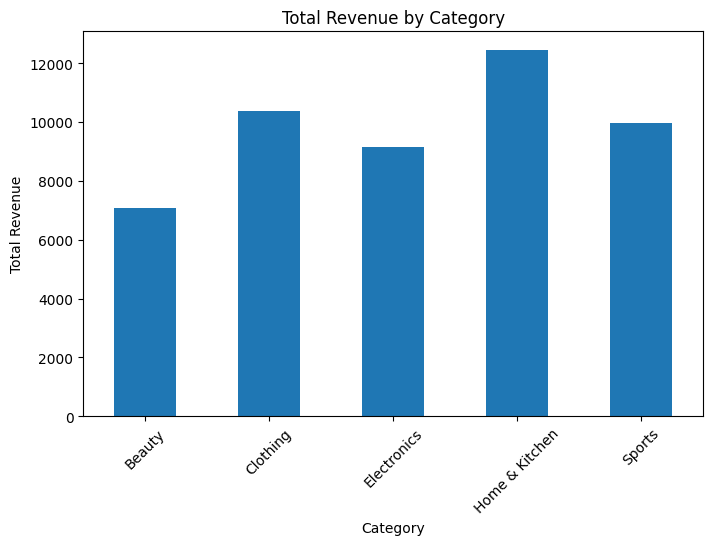

In [520]:
category_revenue.plot(kind = 'bar', figsize = (8,5))
plt.title("Total Revenue by Category")
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation = 45)
plt.show()

In [521]:
category_profit = df.groupby('category')['profit'].sum()
print(category_profit)

category
Beauty            2551.13
Clothing          3574.54
Electronics       3191.44
Home & Kitchen    4588.35
Sports            3508.32
Name: profit, dtype: float64


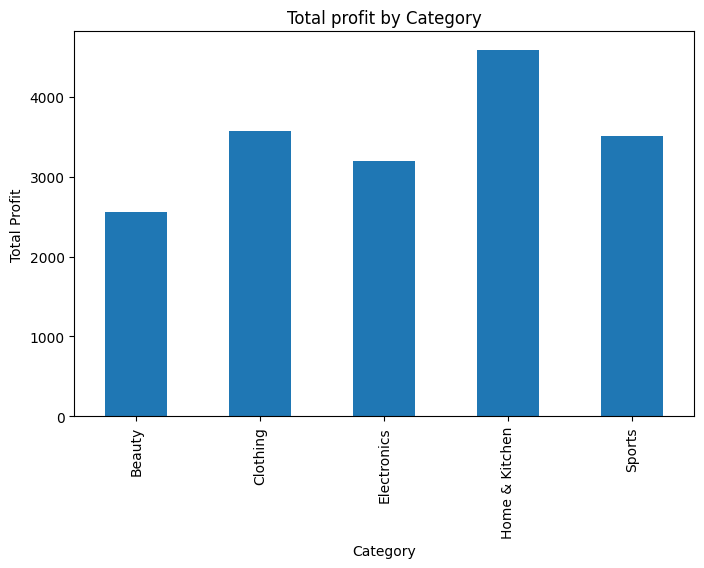

In [522]:
category_profit.plot(kind = 'bar', figsize=(8,5))
plt.title('Total profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.show()

In [523]:
category_margin = (category_profit / category_revenue) * 100
print(category_margin.round(2))

category
Beauty            36.12
Clothing          34.51
Electronics       34.91
Home & Kitchen    36.84
Sports            35.18
dtype: float64


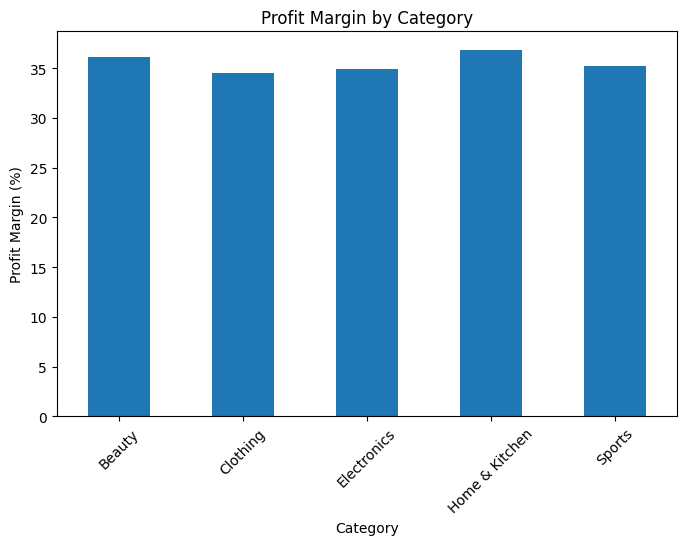

In [524]:
category_margin.plot(kind = 'bar', figsize = (8,5))
plt.title('Profit Margin by Category')
plt.xlabel('Category')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=45)
plt.show()

In [525]:
region_revenue = df.groupby('region')['revenue'].sum()
print(region_revenue)

region
East       11658.30
North      14098.65
South      11516.35
Unknown      392.50
West       11323.20
Name: revenue, dtype: float64


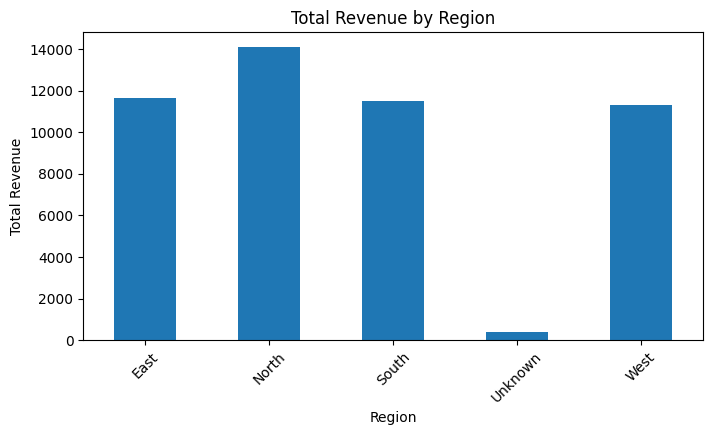

In [526]:
region_revenue.plot(kind = 'bar', figsize = (8,4))
plt.title('Total Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.xticks(rotation = 45)
plt.show()

In [527]:
region_profit = df.groupby('region')['profit'].sum()

print(region_profit)

region
East       4086.76
North      5221.08
South      4114.09
Unknown     128.47
West       3863.38
Name: profit, dtype: float64


In [528]:
region_margin = (region_profit / region_revenue) * 100

print(region_margin.round(2))

region
East       35.05
North      37.03
South      35.72
Unknown    32.73
West       34.12
dtype: float64


In [529]:
payment_revenue = df.groupby('payment_method')['revenue'].sum()

print(payment_revenue)

payment_method
Bank Transfer    11093.50
Card             13961.10
Cash             11868.05
Mobile Wallet    11584.45
Unknown            481.90
Name: revenue, dtype: float64


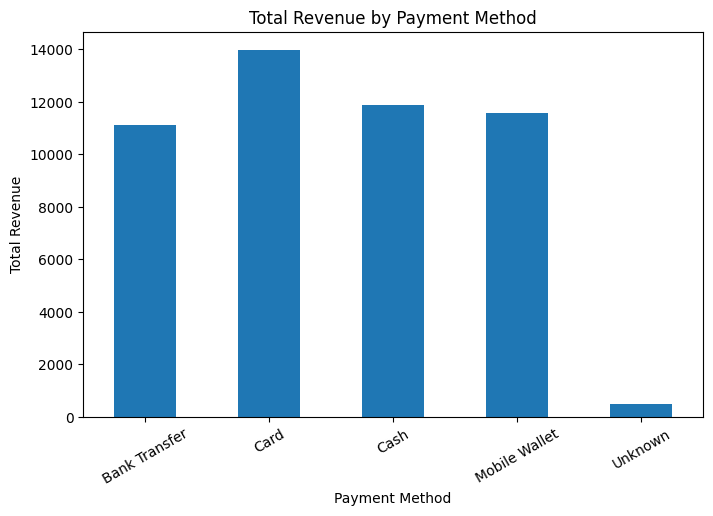

In [530]:
payment_revenue.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Total Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.show()

In [531]:
payment_profit = df.groupby('payment_method')['profit'].sum()

print(payment_profit)

payment_method
Bank Transfer    3844.23
Card             5081.61
Cash             4092.17
Mobile Wallet    4203.40
Unknown           192.37
Name: profit, dtype: float64


In [532]:
payment_margin = (payment_profit / payment_revenue) * 100

print(payment_margin.round(2))

payment_method
Bank Transfer    34.65
Card             36.40
Cash             34.48
Mobile Wallet    36.28
Unknown          39.92
dtype: float64


In [533]:
customer_revenue = df.groupby('customer_type')['revenue'].sum()

print(customer_revenue)

customer_type
New          24889.1
Returning    23748.2
Unknown        351.7
Name: revenue, dtype: float64


In [534]:
customer_profit = df.groupby('customer_type')['profit'].sum()

print(customer_profit)

customer_type
New          8902.24
Returning    8421.11
Unknown        90.43
Name: profit, dtype: float64


In [535]:
customer_margin = (customer_profit / customer_revenue) * 100

print(customer_margin.round(2))

customer_type
New          35.77
Returning    35.46
Unknown      25.71
dtype: float64


In [536]:
product_revenue = df.groupby('product')['revenue'].sum()

print(product_revenue.sort_values(ascending=False))

product
Cookware Set      5552.00
Jacket            4477.50
Running Shoes     4324.80
Perfume           4291.20
Blender           4001.25
Headphones        3537.00
Jeans             3320.10
Dumbbells         2590.00
Keyboard          2121.60
Hoodie            2010.20
USB Hub           1826.40
Desk Lamp         1743.00
Wireless Mouse    1656.90
Yoga Mat          1628.75
Sports Bottle     1429.20
Moisturizer       1159.40
Water Bottle      1157.60
Shampoo            814.80
Face Wash          796.80
T-Shirt            550.50
Name: revenue, dtype: float64


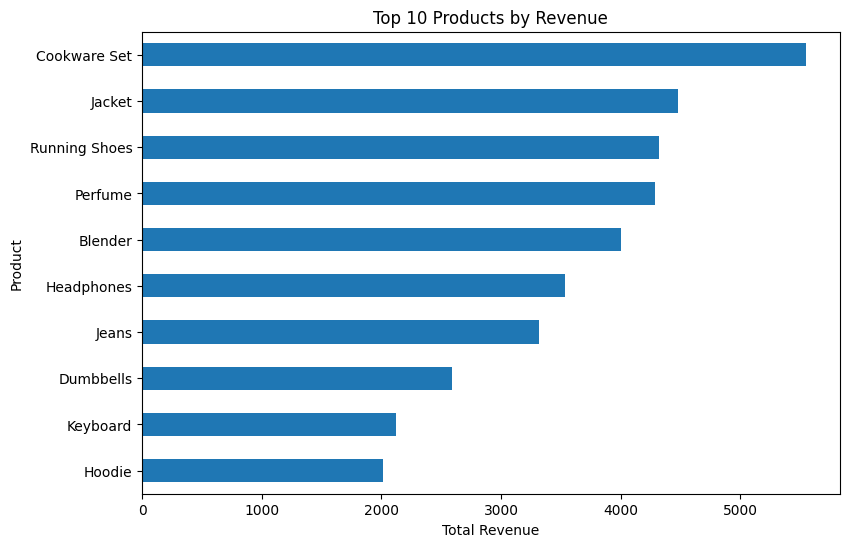

In [537]:
top_10_products = product_revenue.sort_values(ascending=False).head(10)

top_10_products.plot(kind='barh', figsize=(9, 6))

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.show()

In [538]:
product_profit = df.groupby('product')['profit'].sum()

print(product_profit.sort_values(ascending=False))

product
Cookware Set      2174.48
Perfume           1610.42
Running Shoes     1601.04
Jacket            1522.21
Blender           1324.53
Headphones        1299.42
Jeans             1212.68
Dumbbells          873.72
Desk Lamp          671.85
USB Hub            659.64
Keyboard           659.03
Hoodie             658.37
Wireless Mouse     573.35
Yoga Mat           535.23
Sports Bottle      498.33
Water Bottle       417.49
Moisturizer        399.61
Face Wash          273.95
Shampoo            267.15
T-Shirt            181.28
Name: profit, dtype: float64


In [539]:
product_margin = (product_profit / product_revenue) * 100

print(product_margin.sort_values(ascending=False).round(2))

product
Cookware Set      39.17
Desk Lamp         38.55
Perfume           37.53
Running Shoes     37.02
Headphones        36.74
Jeans             36.53
USB Hub           36.12
Water Bottle      36.07
Sports Bottle     34.87
Wireless Mouse    34.60
Moisturizer       34.47
Face Wash         34.38
Jacket            34.00
Dumbbells         33.73
Blender           33.10
T-Shirt           32.93
Yoga Mat          32.86
Shampoo           32.79
Hoodie            32.75
Keyboard          31.06
dtype: float64


In [540]:
df['month'] = df['order_date'].dt.month

monthly_revenue = df.groupby('month')['revenue'].sum()

print(monthly_revenue)

month
1     3812.20
2     4807.25
3     3684.05
4     4128.65
5     3864.30
6     3760.20
7     6723.50
8     4655.30
9     3404.75
10    3132.55
11    3169.05
12    3847.20
Name: revenue, dtype: float64


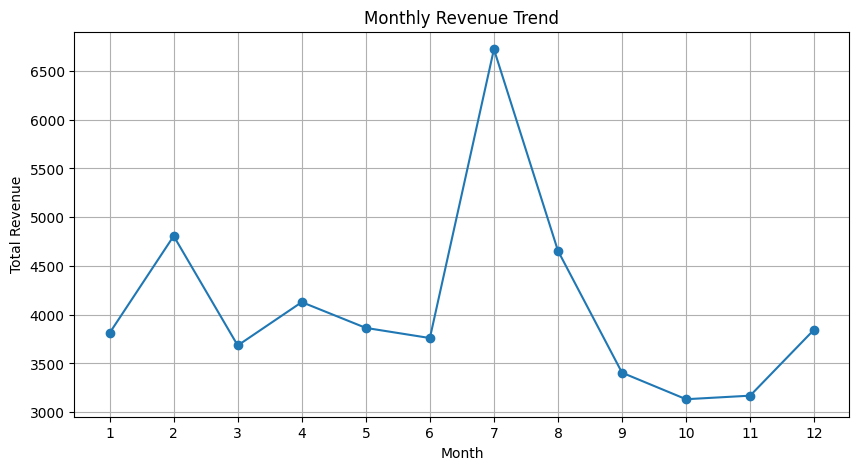

In [541]:
monthly_revenue.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [542]:
monthly_profit = df.groupby('month')['profit'].sum()

print(monthly_profit)

month
1     1402.79
2     1793.98
3     1454.06
4     1458.70
5     1460.74
6     1303.04
7     2248.70
8     1474.25
9     1251.35
10    1078.01
11    1074.34
12    1413.82
Name: profit, dtype: float64


In [543]:
monthly_margin = (monthly_profit / monthly_revenue) * 100

print(monthly_margin.round(2))


month
1     36.80
2     37.32
3     39.47
4     35.33
5     37.80
6     34.65
7     33.45
8     31.67
9     36.75
10    34.41
11    33.90
12    36.75
dtype: float64


In [544]:
df['day_name'] = df['order_date'].dt.day_name()

day_revenue = df.groupby('day_name')['revenue'].sum()

print(day_revenue)


day_name
Friday       6489.20
Monday       6187.50
Saturday     6951.15
Sunday       6476.10
Thursday     9628.70
Tuesday      5453.20
Wednesday    7803.15
Name: revenue, dtype: float64


In [545]:
days_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_revenue = day_revenue.reindex(days_order)

print(day_revenue)

day_name
Monday       6187.50
Tuesday      5453.20
Wednesday    7803.15
Thursday     9628.70
Friday       6489.20
Saturday     6951.15
Sunday       6476.10
Name: revenue, dtype: float64


In [546]:
day_profit = df.groupby('day_name')['profit'].sum()

print(day_profit.reindex(days_order))

day_name
Monday       2249.10
Tuesday      1921.17
Wednesday    2782.17
Thursday     3348.39
Friday       2184.32
Saturday     2560.48
Sunday       2368.15
Name: profit, dtype: float64


In [547]:
day_margin = (day_profit / day_revenue) * 100

print(day_margin.reindex(days_order).round(2))


day_name
Monday       36.35
Tuesday      35.23
Wednesday    35.65
Thursday     34.78
Friday       33.66
Saturday     36.84
Sunday       36.57
dtype: float64


In [548]:
product_quantity = df.groupby('product')['quantity'].sum()

print(product_quantity.sort_values(ascending=False))

product
Wireless Mouse    104
Perfume            97
Headphones         88
Jeans              88
Sports Bottle      88
USB Hub            83
Water Bottle       80
Blender            79
Cookware Set       77
Keyboard           76
Face Wash          75
Dumbbells          71
Yoga Mat           71
Running Shoes      70
Desk Lamp          69
Shampoo            66
Jacket             64
Hoodie             60
Moisturizer        58
T-Shirt            41
Name: quantity, dtype: int64


In [549]:
category_quantity = df.groupby('category')['quantity'].sum()

print(category_quantity.sort_values(ascending=False))

category
Electronics       351
Home & Kitchen    305
Sports            300
Beauty            296
Clothing          253
Name: quantity, dtype: int64


In [550]:
category_avg_price = df.groupby('category')['unit_price'].mean()
print(category_avg_price.sort_values(ascending=False).round(2))

category
Clothing          43.99
Home & Kitchen    43.45
Sports            37.39
Electronics       29.04
Beauty            25.00
Name: unit_price, dtype: float64


In [551]:
category_discount = df.groupby('category')['discount_rate'].mean() * 100
print(category_discount.sort_values(ascending=False).round(2))

category
Electronics       10.53
Clothing          10.28
Beauty             9.89
Home & Kitchen     9.85
Sports             9.85
Name: discount_rate, dtype: float64


In [552]:
correlation = df.corr(numeric_only=True)
print(correlation.round(2))

               unit_price  quantity  discount_rate  revenue  cost  profit  \
unit_price           1.00      0.03          -0.08     0.70  0.69    0.63   
quantity             0.03      1.00          -0.09     0.63  0.63    0.56   
discount_rate       -0.08     -0.09           1.00    -0.21 -0.12   -0.33   
revenue              0.70      0.63          -0.21     1.00  0.97    0.93   
cost                 0.69      0.63          -0.12     0.97  1.00    0.81   
profit               0.63      0.56          -0.33     0.93  0.81    1.00   
month               -0.01     -0.05          -0.02    -0.03 -0.01   -0.06   

               month  
unit_price     -0.01  
quantity       -0.05  
discount_rate  -0.02  
revenue        -0.03  
cost           -0.01  
profit         -0.06  
month           1.00  


In [553]:
import seaborn as sns

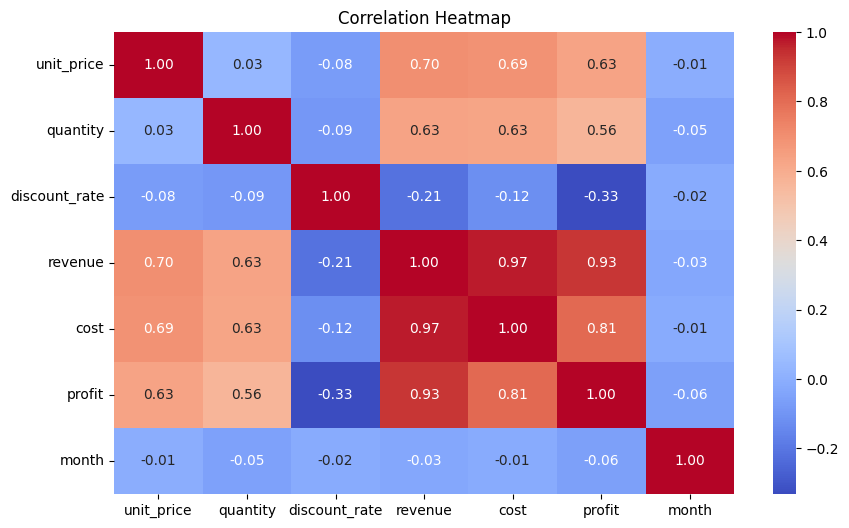

In [554]:
plt.figure(figsize=(10,6))

sns.heatmap(correlation, annot =True, cmap ='coolwarm', fmt = '.2f')
plt.title('Correlation Heatmap')
plt.show()

In [555]:
region_analysis = df.groupby('region').agg({'revenue': 'sum',
                                            'profit': 'sum',
                                            'quantity': 'sum'}).round(2)
region_analysis

,revenue,profit,quantity
region,,,
East,11658.30,4086.76,365
North,14098.65,5221.08,411
South,11516.35,4114.09,362
Unknown,392.50,128.47,12
West,11323.20,3863.38,355


In [556]:
region_analysis['profit_margin'] = (region_analysis['profit']/region_analysis['revenue']) * 100
region_analysis.round(2)

,revenue,profit,quantity,profit_margin
region,,,,
East,11658.30,4086.76,365,35.05
North,14098.65,5221.08,411,37.03
South,11516.35,4114.09,362,35.72
Unknown,392.50,128.47,12,32.73
West,11323.20,3863.38,355,34.12


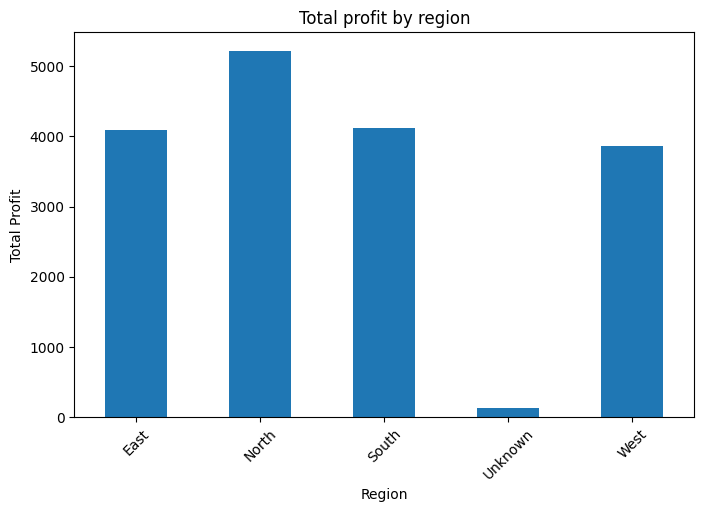

In [557]:
region_profit.plot(kind = 'bar', figsize= (8,5), title = 'Total profit by region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.show()

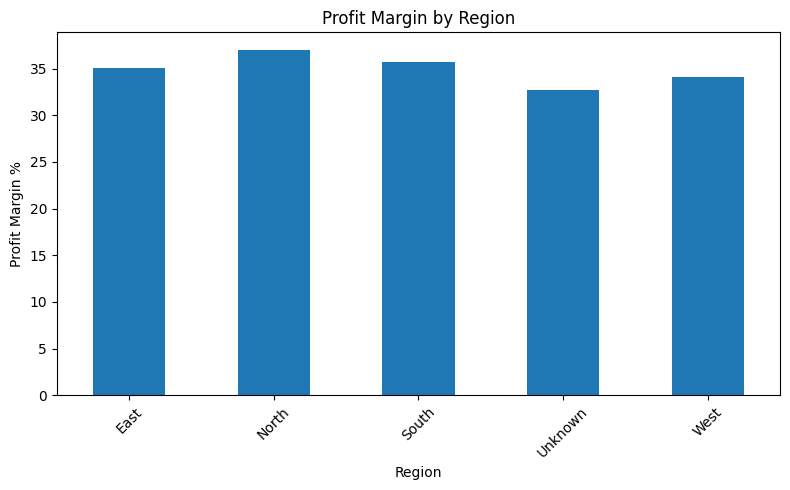

In [558]:
region_margin.plot(kind = 'bar', figsize=(8,5), title = 'Profit Margin by Region')
plt.xlabel('Region')
plt.ylabel('Profit Margin %')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

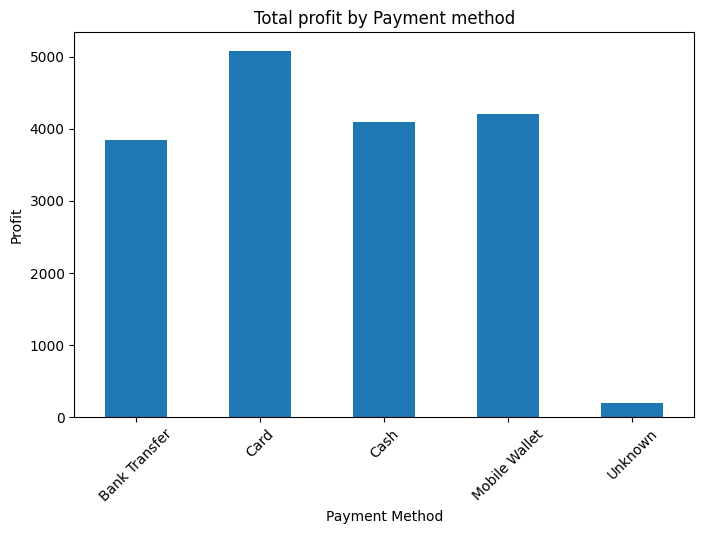

In [559]:
payment_profit.plot(kind = 'bar', figsize=(8,5), title = 'Total profit by Payment method')
plt.xlabel('Payment Method')
plt.ylabel('Profit')
plt.xticks(rotation = 45)
plt.show()

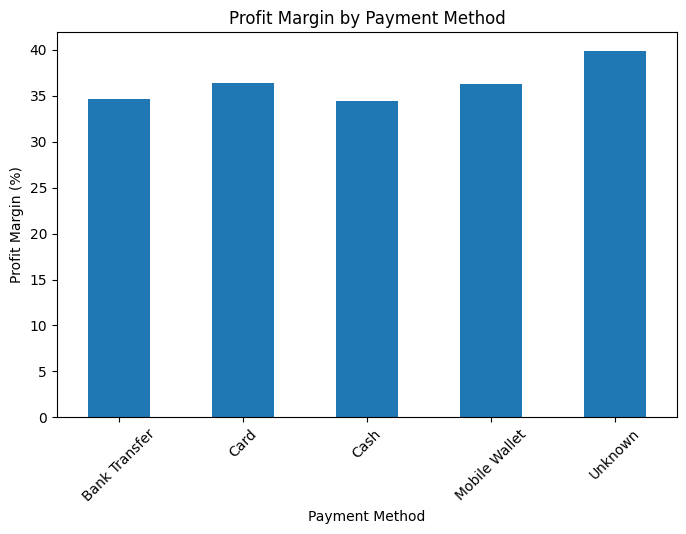

payment_method
Bank Transfer    34.65
Card             36.40
Cash             34.48
Mobile Wallet    36.28
Unknown          39.92
dtype: float64


In [560]:
payment_margin.plot(
    kind='bar',
    figsize=(8,5),
    title='Profit Margin by Payment Method'
)

plt.xlabel('Payment Method')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=45)
plt.show()

print(payment_margin.round(2))

In [561]:
print(profit_margin.round(2))

35.55


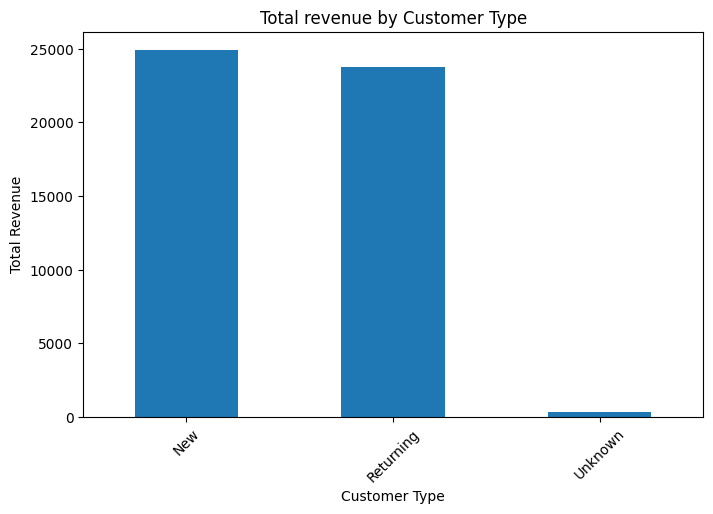

In [562]:
customer_revenue.plot(kind = 'bar', figsize = (8,5), title = 'Total revenue by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Total Revenue')
plt.xticks(rotation = 45)
plt.show()

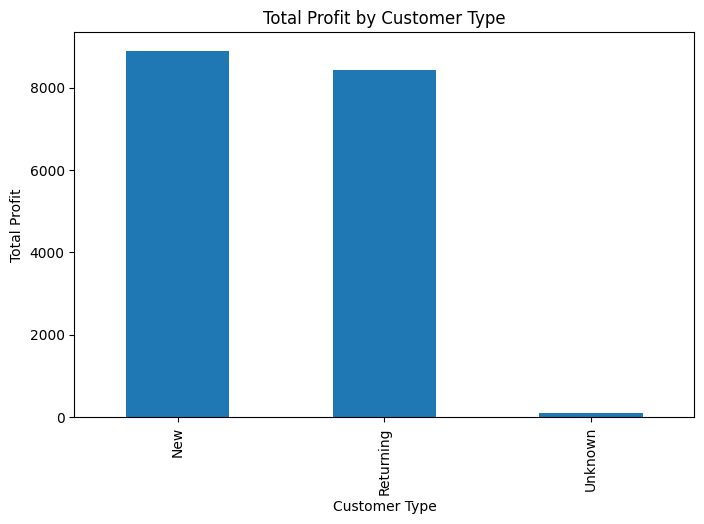

In [563]:
customer_profit.plot(kind = 'bar', figsize=(8,5), title = 'Total Profit by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Total Profit')
plt.show()

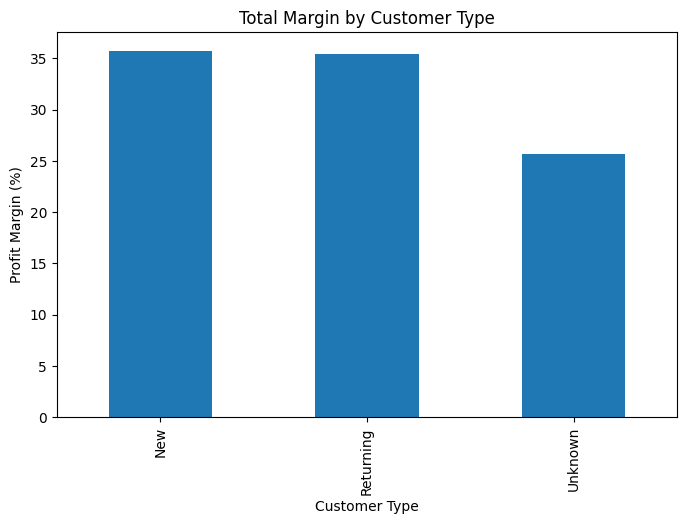

In [564]:
customer_margin.plot(kind = 'bar', figsize=(8,5), title = 'Total Margin by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Profit Margin (%)')
plt.show()

In [565]:
customer_analysis = df.groupby('customer_type').agg({'revenue':'sum',
                                                     'profit':'sum',
                                                     'quantity':'sum'})
customer_analysis['profit_margin'] = (customer_analysis['profit']/customer_analysis['revenue']) * 100
customer_analysis.round(2)

,revenue,profit,quantity,profit_margin
customer_type,,,,
New,24889.1,8902.24,766,35.77
Returning,23748.2,8421.11,729,35.46
Unknown,351.7,90.43,10,25.71


In [566]:
aov = df['revenue'].sum() / df['order_id'].nunique()

print(f"Average Order Value: {aov:.2f}")

Average Order Value: 97.98
